In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, cohen_kappa_score, matthews_corrcoef
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("28-10-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

cat_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_cols
print(f"Total features: {len(all_feature_names)}")

df_X_train = pd.DataFrame(X_train_trans, columns=all_feature_names)
df_X_test = pd.DataFrame(X_test_trans, columns=all_feature_names)

Loaded dataset: 23486 rows, 23 columns
Total features: 20


In [3]:
rf_base = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, n_jobs=-1)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rfecv = RFECV(
    estimator=rf_base,
    step=1,
    cv=cv_strat,
    scoring='f1_macro',
    min_features_to_select=1,
    n_jobs=-1
)
rfecv.fit(X_train_trans, y_train)

print(f"Optimal Number of Features (k*): {rfecv.n_features_}")
df_rfe = pd.DataFrame({
    'Feature': all_feature_names,
    'RFE_Ranking': rfecv.ranking_,
    'Selected': rfecv.support_
}).sort_values(by=['RFE_Ranking', 'Feature']).reset_index(drop=True)

display(df_rfe)

Optimal Number of Features (k*): 19


,Feature,RFE_Ranking,Selected
0,Age,1,True
1,Department Name_Dresses,1,True
2,Department Name_Intimate,1,True
3,Department Name_Jackets,1,True
4,Department Name_Tops,1,True
5,Division Name_General Petite,1,True
6,Division Name_Intimates,1,True
7,Exclamation_Count,1,True
8,Fit_Issue_Word_Count,1,True
9,Negative_Word_Count,1,True


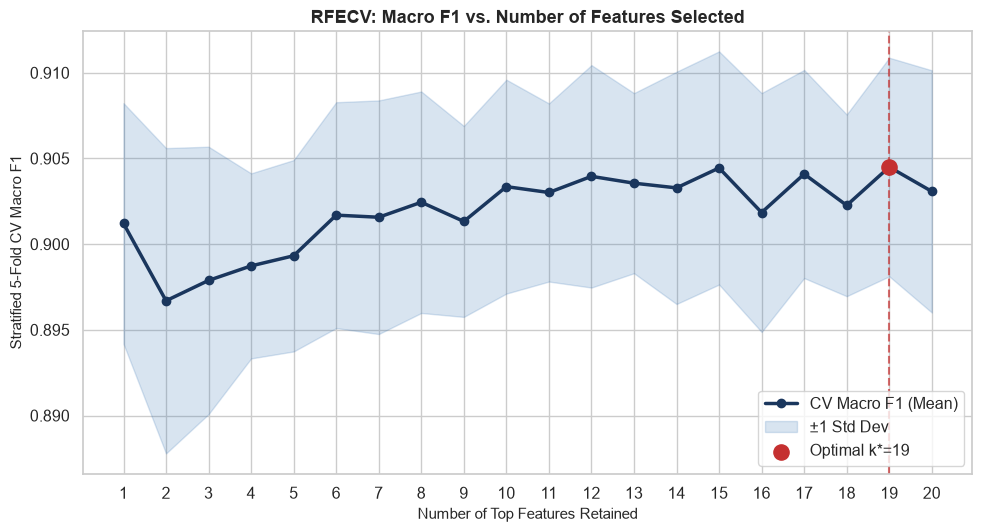

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
cv_means = rfecv.cv_results_['mean_test_score']
cv_stds = rfecv.cv_results_['std_test_score']
n_feats_range = range(1, len(cv_means) + 1)

ax.plot(n_feats_range, cv_means, marker='o', color='#1A365D', linewidth=2.5, markersize=6, label='CV Macro F1 (Mean)')
ax.fill_between(n_feats_range, cv_means - cv_stds, cv_means + cv_stds, color='#2B6CB0', alpha=0.18, label='±1 Std Dev')

best_idx = rfecv.n_features_ - 1
ax.scatter([rfecv.n_features_], [cv_means[best_idx]], color='#C53030', s=120, zorder=5, label=f'Optimal k*={rfecv.n_features_}')
ax.axvline(rfecv.n_features_, color='#C53030', linestyle='--', alpha=0.7)

ax.set_title("RFECV: Macro F1 vs. Number of Features Selected", fontsize=13, fontweight='bold')
ax.set_xlabel("Number of Top Features Retained", fontsize=11)
ax.set_ylabel("Stratified 5-Fold CV Macro F1", fontsize=11)
ax.set_xticks(list(n_feats_range))
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [5]:
rf_full = RandomForestClassifier(n_estimators=150, max_depth=7, random_state=42, n_jobs=-1)
rf_full.fit(X_train_trans, y_train)

perm_res = permutation_importance(
    rf_full, X_test_trans, y_test,
    n_repeats=10, random_state=42,
    scoring='f1_macro', n_jobs=-1
)

df_perm = pd.DataFrame({
    'Feature': all_feature_names,
    'Permutation_Importance_Mean': perm_res.importances_mean,
    'Permutation_Importance_Std': perm_res.importances_std
}).sort_values(by='Permutation_Importance_Mean', ascending=False).reset_index(drop=True)
df_perm['Permutation_Rank'] = range(1, len(df_perm) + 1)

display(df_perm.head(10))

,Feature,Permutation_Importance_Mean,Permutation_Importance_Std,Permutation_Rank
0,Rating,0.298670,0.005745,1
1,Rating_x_Sentiment,0.136123,0.003440,2
2,Sentiment_Neg,0.005506,0.001285,3
3,Negative_Word_Count,0.005353,0.001082,4
4,Sentiment_Pos,0.001962,0.001175,5
5,Fit_Issue_Word_Count,0.001457,0.000856,6
6,Positive Feedback Count,0.001324,0.001021,7
7,Review_Length,0.000899,0.001273,8
8,Positive_Word_Count,0.000843,0.000922,9
9,Review_Word_Count,0.000824,0.000851,10


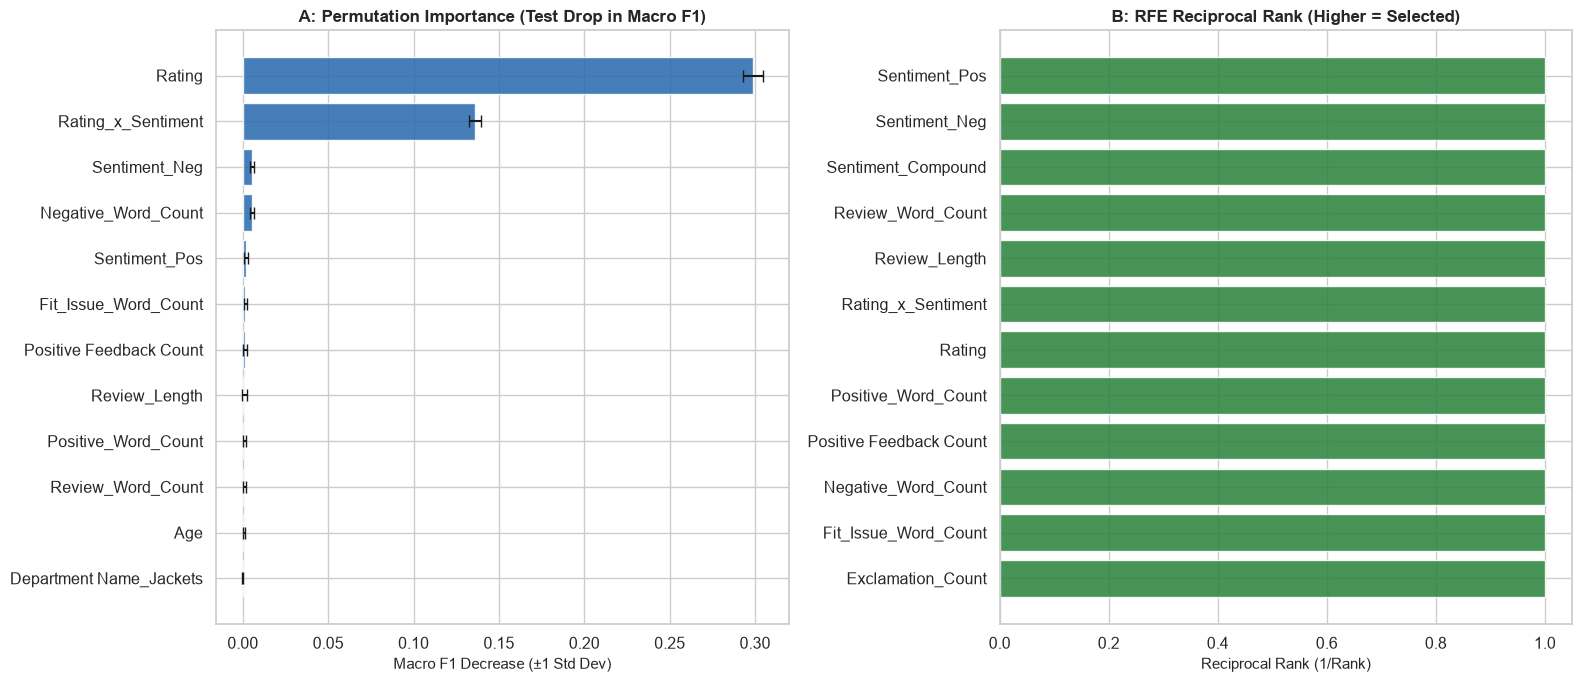

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_perm_plot = df_perm.sort_values(by='Permutation_Importance_Mean', ascending=True).tail(12)
axes[0].barh(top_perm_plot['Feature'], top_perm_plot['Permutation_Importance_Mean'], 
            xerr=top_perm_plot['Permutation_Importance_Std'], color='#2B6CB0', alpha=0.88, capsize=4)
axes[0].set_title("A: Permutation Importance (Test Drop in Macro F1)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Macro F1 Decrease (±1 Std Dev)", fontsize=11)

df_rfe_plot = df_rfe.sort_values(by=['RFE_Ranking', 'Feature'], ascending=[False, True]).tail(12)
colors = ['#2E8540' if sel else '#A0AEC0' for sel in df_rfe_plot['Selected']]
axes[1].barh(df_rfe_plot['Feature'], [1.0 / r for r in df_rfe_plot['RFE_Ranking']], color=colors, alpha=0.88)
axes[1].set_title("B: RFE Reciprocal Rank (Higher = Selected)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Reciprocal Rank (1/Rank)", fontsize=11)

plt.tight_layout()
plt.show()

In [7]:
pca = PCA(random_state=42)
pca.fit(X_train_trans)

cum_var = np.cumsum(pca.explained_variance_ratio_)
n_comp_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_comp_95 = int(np.argmax(cum_var >= 0.95) + 1)

print(f"Components for 90% Variance: {n_comp_90}")
print(f"Components for 95% Variance: {n_comp_95}")

df_pca = pd.DataFrame({
    'Principal_Component': [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
    'Explained_Variance_Ratio': pca.explained_variance_ratio_,
    'Cumulative_Explained_Variance': cum_var
})
display(df_pca.head(10))

Components for 90% Variance: 10
Components for 95% Variance: 12


,Principal_Component,Explained_Variance_Ratio,Cumulative_Explained_Variance
0,PC1,0.272126,0.272126
1,PC2,0.178590,0.450716
2,PC3,0.081190,0.531906
3,PC4,0.073142,0.605048
4,PC5,0.067231,0.672278
5,PC6,0.063746,0.736024
6,PC7,0.057645,0.793669
7,PC8,0.054873,0.848543
8,PC9,0.039241,0.887783
9,PC10,0.034499,0.922282


In [8]:
bench_csv = "feature_selection_retrained_models_benchmark.csv"
if not os.path.exists(bench_csv):
    bench_csv = os.path.join("28-10-2026", "Task 1", "feature_selection_retrained_models_benchmark.csv")

df_benchmark = pd.read_csv(bench_csv)
display(df_benchmark)

,Model_Architecture,Feature_Selection_Strategy,Dimension_Count,Accuracy,Precision,Recall,F1_Score,Macro_F1,ROC_AUC,Cohen_Kappa,MCC,Train_Time_s,Inference_Latency_us
0,Random Forest,All Features (Baseline),20,0.9419,0.9734,0.9555,0.9643,0.9038,0.9746,0.8076,0.8086,1.052,15.3
1,Logistic Regression,All Features (Baseline),20,0.9430,0.9620,0.9689,0.9654,0.9011,0.9778,0.8022,0.8024,0.089,0.2
2,Random Forest,RFE Optimal Subset (19 Feats),19,0.9406,0.9726,0.9547,0.9636,0.9017,0.9753,0.8034,0.8044,1.254,15.5
3,Logistic Regression,RFE Optimal Subset (19 Feats),19,0.9430,0.9620,0.9689,0.9654,0.9011,0.9778,0.8022,0.8024,0.073,0.2
4,Random Forest,Permutation Top-19 Feats,19,0.9410,0.9721,0.9557,0.9638,0.9021,0.9746,0.8043,0.8051,1.057,19.1
5,Logistic Regression,Permutation Top-19 Feats,19,0.9419,0.9619,0.9676,0.9648,0.8995,0.9776,0.7990,0.7991,0.090,0.2
6,Random Forest,PCA 95% Var (12 Comps),12,0.9298,0.9517,0.9635,0.9576,0.8770,0.9708,0.7541,0.7546,2.395,17.4
7,Logistic Regression,PCA 95% Var (12 Comps),12,0.9361,0.9502,0.9733,0.9616,0.8856,0.9770,0.7714,0.7734,0.032,0.2
8,Random Forest,PCA 90% Var (10 Comps),10,0.9304,0.9501,0.9661,0.9580,0.8771,0.9697,0.7544,0.7553,2.349,18.0
9,Logistic Regression,PCA 90% Var (10 Comps),10,0.9372,0.9505,0.9744,0.9623,0.8874,0.9769,0.7749,0.7771,0.029,0.2


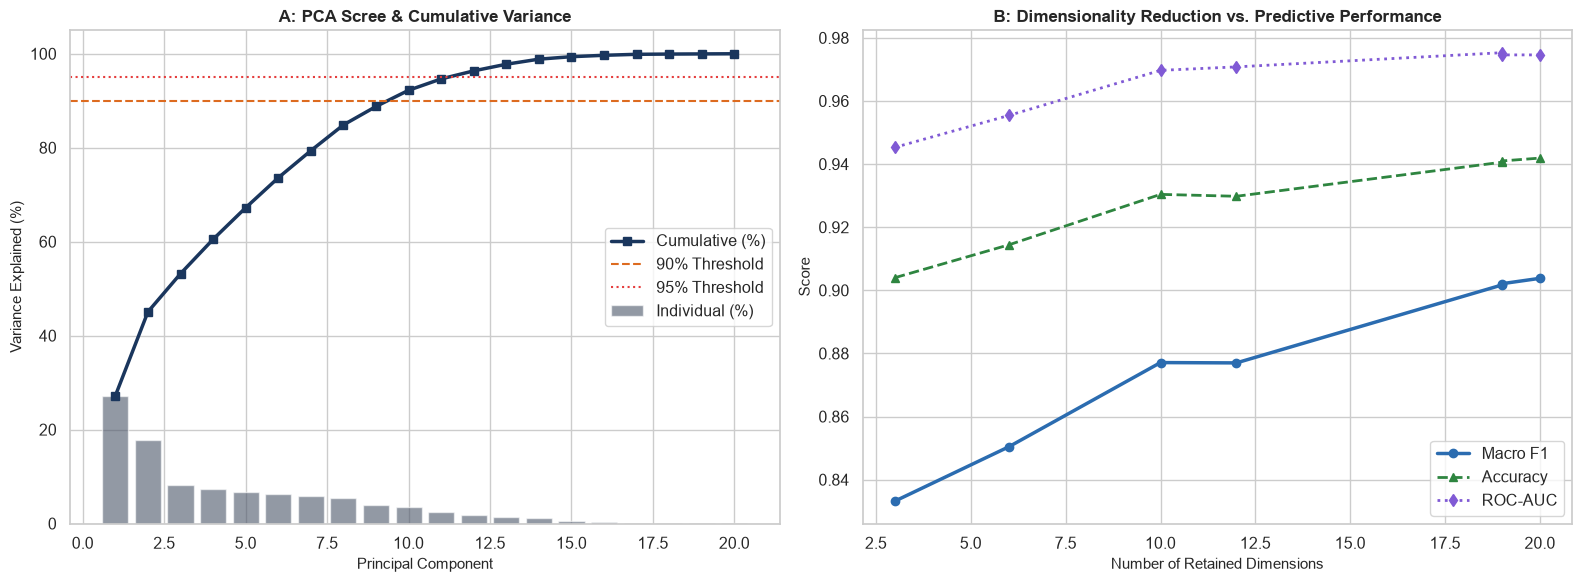

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x_pc = range(1, len(cum_var) + 1)
axes[0].bar(x_pc, pca.explained_variance_ratio_ * 100, color='#4A5568', alpha=0.6, label='Individual (%)')
axes[0].plot(x_pc, cum_var * 100, marker='s', color='#1A365D', linewidth=2.5, label='Cumulative (%)')
axes[0].axhline(90, color='#DD6B20', linestyle='--', label='90% Threshold')
axes[0].axhline(95, color='#E53E3E', linestyle=':', label='95% Threshold')
axes[0].set_title("A: PCA Scree & Cumulative Variance", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Principal Component", fontsize=11)
axes[0].set_ylabel("Variance Explained (%)", fontsize=11)
axes[0].legend(loc='center right', frameon=True)

df_rf_bench = df_benchmark[df_benchmark['Model_Architecture'] == 'Random Forest'].sort_values(by='Dimension_Count', ascending=True)
axes[1].plot(df_rf_bench['Dimension_Count'], df_rf_bench['Macro_F1'], marker='o', linewidth=2.5, color='#2B6CB0', label='Macro F1')
axes[1].plot(df_rf_bench['Dimension_Count'], df_rf_bench['Accuracy'], marker='^', linewidth=2.0, color='#2E8540', linestyle='--', label='Accuracy')
axes[1].plot(df_rf_bench['Dimension_Count'], df_rf_bench['ROC_AUC'], marker='d', linewidth=2.0, color='#805AD5', linestyle=':', label='ROC-AUC')

axes[1].set_title("B: Dimensionality Reduction vs. Predictive Performance", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Retained Dimensions", fontsize=11)
axes[1].set_ylabel("Score", fontsize=11)
axes[1].legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()